# ZooKeeper: issue links and duplicates

In [ ]:
!pip install transformers datasets accelerate jira tqdm scikit-learn pandas numpy torch pyvis

In [2]:
import re
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, confusion_matrix
from transformers import BertTokenizer, BertForSequenceClassification, get_linear_schedule_with_warmup
from torch.optim import AdamW
from tqdm.auto import tqdm
from jira import JIRA
import time
import json
import matplotlib.pyplot as plt

jira = JIRA('https://issues.apache.org/jira')

In [4]:
def collect_zookeeper_links(jira_conn):
    jql = 'project=ZOOKEEPER'

    print("Fetching all ZooKeeper issues...")
    issues = jira_conn.search_issues(jql, maxResults=False, fields='summary,issuetype,description,created')
    print(f"Found {len(issues)} issues")

    issue_types = {}
    issue_descriptions = {}
    issue_created = {}
    for issue in issues:
        issue_types[issue.key] = issue.fields.issuetype.name
        issue_descriptions[issue.key] = issue.fields.description or ''
        issue_created[issue.key] = issue.fields.created

    link_data = []
    total_links = 0
    kept_links = 0

    for i, issue in enumerate(tqdm(issues, desc="Processing issues")):
        issue_key = issue.key
        issue_num = int(issue_key.split('-')[1])
        issue_type = issue_types.get(issue_key, 'Unknown')
        issue_description = issue_descriptions.get(issue_key, '')
        issue_created_date = issue_created.get(issue_key, '')

        try:
            issue_with_links = jira_conn.issue(issue_key, fields='issuelinks')
            if not issue_with_links.fields.issuelinks:
                continue
        except Exception as e:
            continue

        for link in issue_with_links.fields.issuelinks:
            total_links += 1

            linked_key = None
            link_type = None
            link_description = None

            if hasattr(link, 'inwardIssue') and link.inwardIssue:
                linked_key = link.inwardIssue.key
                if hasattr(link, 'type'):
                    link_type = link.type.inward
                    if hasattr(link.type, 'description'):
                        link_description = link.type.description
            elif hasattr(link, 'outwardIssue') and link.outwardIssue:
                linked_key = link.outwardIssue.key
                if hasattr(link, 'type'):
                    link_type = link.type.outward
                    if hasattr(link.type, 'description'):
                        link_description = link.type.description

            if not linked_key:
                continue

            if not linked_key.startswith('ZOOKEEPER-'):
                continue

            try:
                linked_num = int(linked_key.split('-')[1])
            except ValueError:
                continue

            linked_type = issue_types.get(linked_key, 'Unknown')
            linked_description = issue_descriptions.get(linked_key, '')
            linked_created_date = issue_created.get(linked_key, '')

            if issue_num > linked_num:
                kept_links += 1
                link_data.append({
                    'Issue': issue_key,
                    'Issue_Number': issue_num,
                    'Issue_Type': issue_type,
                    'Issue_Description': issue_description,
                    'Issue_Created': issue_created_date,
                    'Linked_Issue': linked_key,
                    'Linked_Issue_Number': linked_num,
                    'Linked_Issue_Type': linked_type,
                    'Linked_Issue_Description': linked_description,
                    'Linked_Issue_Created': linked_created_date,
                    'Link_Type': link_type,
                    'Link_Description': link_description
                })

    print(f"\nTotal links: {total_links}")
    print(f"Links kept: {kept_links}")

    df = pd.DataFrame(link_data)

    if len(df) > 0:
        df = df.sort_values('Issue_Number', ascending=False)
        df = df[['Issue', 'Issue_Number', 'Issue_Type', 'Issue_Description', 'Issue_Created',
                 'Linked_Issue', 'Linked_Issue_Number', 'Linked_Issue_Type', 'Linked_Issue_Description', 'Linked_Issue_Created',
                 'Link_Type', 'Link_Description']]
    return df

In [5]:
zookeeper_links_df = collect_zookeeper_links(jira)
zookeeper_links_df.to_csv('zookeeper_links.csv', index=False)

print("\nSummary:")
print(f"Total links: {len(zookeeper_links_df)}")
print(f"Unique issues: {zookeeper_links_df['Issue'].nunique()}")
print(f"Unique linked issues: {zookeeper_links_df['Linked_Issue'].nunique()}")

print("\nLink types:")
link_type_counts = zookeeper_links_df['Link_Type'].value_counts()
for link_type, count in link_type_counts.items():
    print(f"{link_type}: {count}")

Fetching all ZooKeeper issues...
Found 4935 issues



Total links: 2531
Links kept: 1159

Summary:
Total links: 1159
Unique issues: 903
Unique linked issues: 773

Link types:
relates to: 293
is related to: 257
duplicates: 129
is duplicated by: 63
depends upon: 58
supercedes: 51
is a clone of: 33
incorporates: 29
is caused by: 27
blocks: 26
is broken by: 25
is superceded by: 23
is depended upon by: 23
is part of: 21
is blocked by: 20
is required by: 16
requires: 11
contains: 10
fixes: 8
Is contained by: 8
Blocked: 6
is fixed by: 6
breaks: 4
is a child of: 3
is a parent of: 3
causes: 3
Dependent: 2
Parent Feature: 1


In [6]:
from pyvis.network import Network
from IPython.display import HTML

df = pd.read_csv('zookeeper_links.csv')

type_colors = {
    'Bug': 'red',
    'Improvement': 'blue',
    'New Feature': 'green',
    'Task': 'orange',
    'Sub-task': 'orange',
    'Test': 'purple',
    'Unknown': 'gray',
    'Other': 'gray'
}

def get_issue_type(issue_key):
    row = df[df['Issue'] == issue_key]
    if not row.empty and 'Issue_Type' in row.columns:
        return row.iloc[0]['Issue_Type']

    row = df[df['Linked_Issue'] == issue_key]
    if not row.empty and 'Linked_Issue_Type' in row.columns:
        return row.iloc[0]['Linked_Issue_Type']

    return 'Unknown'

g = Network(height=800, width=800, notebook=True, cdn_resources='remote')
g.toggle_hide_edges_on_drag(False)
g.barnes_hut()

for node in set(df['Issue']).union(set(df['Linked_Issue'])):
    issue_type = get_issue_type(node)
    color = type_colors.get(issue_type, 'gray')
    node_num = node.split('-')[1]
    g.add_node(node,
               label=node_num,
               title=f"{node}\nType: {issue_type}",
               color=color,
               size=10)

for _, row in df.iterrows():
    g.add_edge(row['Issue'], row['Linked_Issue'],
               label=row.get('Link_Type', ''))

HTML(g.generate_html())

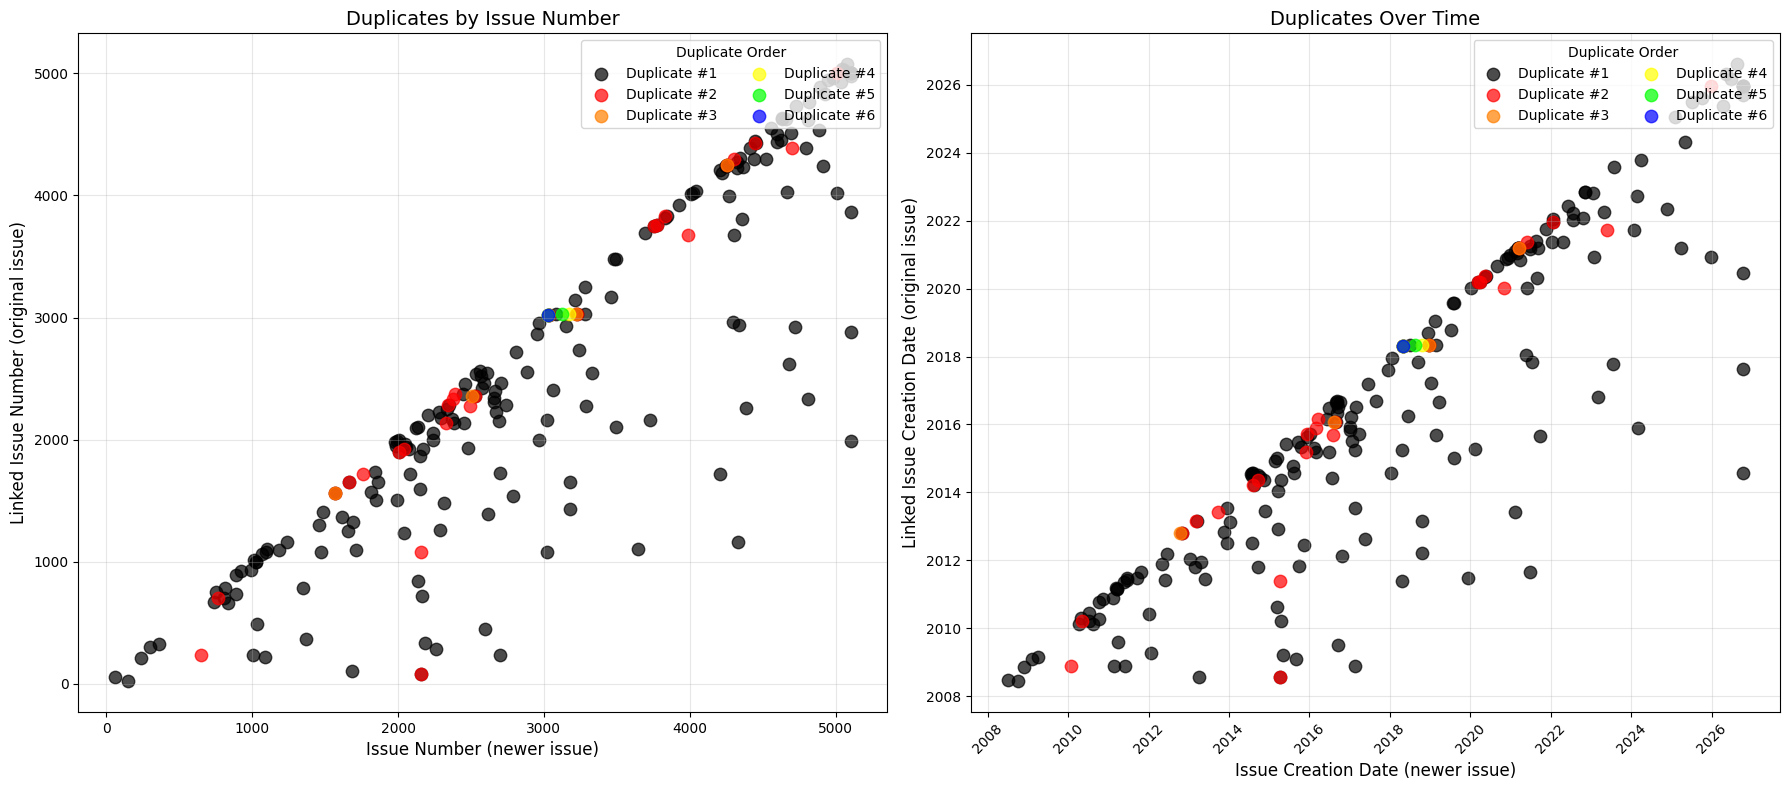

In [7]:
duplicate_links = zookeeper_links_df[zookeeper_links_df['Link_Type'].str.contains('duplicate|clone', case=False, na=False)].copy()

if len(duplicate_links) == 0:
    print("No duplicate links found")
else:
    duplicate_links['Issue_Created_DT'] = pd.to_datetime(duplicate_links['Issue_Created'])
    duplicate_links['Linked_Created_DT'] = pd.to_datetime(duplicate_links['Linked_Issue_Created'])

    duplicate_links['Duplicate_Order'] = duplicate_links.groupby('Linked_Issue').cumcount() + 1

    color_map = {
        1: '#000000',
        2: '#FF0000',
        3: '#FF7F00',
        4: '#FFFF00',
        5: '#00FF00',
        6: '#0000FF',
        7: '#4B0082',
        8: '#8B00FF',
    }

    def get_color(order):
        return color_map.get(order, '#808080')

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))

    for order in sorted(duplicate_links['Duplicate_Order'].unique()):
        data = duplicate_links[duplicate_links['Duplicate_Order'] == order]
        color = get_color(order)
        label = f'Duplicate #{order}'
        ax1.scatter(data['Issue_Number'],
                    data['Linked_Issue_Number'],
                    color=color,
                    alpha=0.7,
                    s=80,
                    label=label)

    ax1.set_xlabel('Issue Number (newer issue)', fontsize=12)
    ax1.set_ylabel('Linked Issue Number (original issue)', fontsize=12)
    ax1.set_title('Duplicates by Issue Number', fontsize=14)
    ax1.legend(title='Duplicate Order', loc='upper right', ncol=2)
    ax1.grid(True, alpha=0.3)

    for order in sorted(duplicate_links['Duplicate_Order'].unique()):
        data = duplicate_links[duplicate_links['Duplicate_Order'] == order]
        color = get_color(order)
        label = f'Duplicate #{order}'
        ax2.scatter(data['Issue_Created_DT'],
                    data['Linked_Created_DT'],
                    color=color,
                    alpha=0.7,
                    s=80,
                    label=label)

    ax2.set_xlabel('Issue Creation Date (newer issue)', fontsize=12)
    ax2.set_ylabel('Linked Issue Creation Date (original issue)', fontsize=12)
    ax2.set_title('Duplicates Over Time', fontsize=14)
    ax2.legend(title='Duplicate Order', loc='upper right', ncol=2)
    ax2.grid(True, alpha=0.3)
    ax2.tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()